In [10]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# List to store our scraped data
books_data = []

# Each page has 20 books. To get at least 200 books, we loop through 10 pages.
num_pages = 10

print("Starting the web scraping process...")

for page in range(1, num_pages + 1):
    # Construct the URL for each page
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    response = requests.get(url)
    
    # Check if the page loaded successfully
    if response.status_code != 200:
        print(f"Failed to retrieve page {page}. Status code: {response.status_code}")
        break
        
    soup = BeautifulSoup(response.text, 'html.parser')
    
    # Find all book containers on the page
    books = soup.find_all('article', class_='product_pod')
    
    for book in books:
        # 1. Extract Title
        title = book.h3.a['title']
        
        # 2. Extract Price (e.g., "£51.77" -> we can clean the symbol later in pandas)
        price_str = book.find('p', class_='price_color').text
        
        # 3. Extract Star Rating (e.g., <p class="star-rating Three"> -> extract "Three")
        star_rating_classes = book.find('p', class_='star-rating')['class']
        # The rating is the second class in the list (e.g., ['star-rating', 'Three'])
        star_rating = star_rating_classes[1] if len(star_rating_classes) > 1 else "Unknown"
        
        # 4. Extract Stock Availability
        availability = book.find('p', class_='instock availability').text.strip()
        
        # Append the dictionary to our list
        books_data.append({
            'Title': title,
            'Price_GBP': price_str,
            'Star_Rating': star_rating,
            'Stock_Availability': availability
        })

    print(f"Successfully scraped page {page}...")

# Convert the list into a Pandas DataFrame
df = pd.DataFrame(books_data)

# Save the dataset to CSV (fulfilling Deliverable #2)
df.to_csv('books_to_scrape_raw.csv', index=False)

print(f"\nScraping complete! Total books collected: {len(df)}")
print("\nFirst 5 rows of your dataset:")
print(df.head())



Starting the web scraping process...
Successfully scraped page 1...
Successfully scraped page 2...
Successfully scraped page 3...
Successfully scraped page 4...
Successfully scraped page 5...
Successfully scraped page 6...
Successfully scraped page 7...
Successfully scraped page 8...
Successfully scraped page 9...
Successfully scraped page 10...

Scraping complete! Total books collected: 200

First 5 rows of your dataset:
                                   Title Price_GBP Star_Rating  \
0                   A Light in the Attic   Â£51.77       Three   
1                     Tipping the Velvet   Â£53.74         One   
2                             Soumission   Â£50.10         One   
3                          Sharp Objects   Â£47.82        Four   
4  Sapiens: A Brief History of Humankind   Â£54.23        Five   

  Stock_Availability  
0           In stock  
1           In stock  
2           In stock  
3           In stock  
4           In stock  


In [11]:
import pandas as pd
import numpy as np

# 1. Load the raw dataset we just created
df = pd.read_csv('books_to_scrape_raw.csv')

print("--- BEFORE CLEANING ---")
print(df.head(), "\n")

# 2. Clean the Price column: Remove '£', 'Â', or any other non-digit/non-decimal characters, then convert to float
df['Price_GBP'] = df['Price_GBP'].astype(str).str.replace(r'[^\d.]', '', regex=True).astype(float)

# 3. Clean the Star Rating column: Map words to integers
rating_mapping = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}
df['Star_Rating'] = df['Star_Rating'].map(rating_mapping)

# 4. Clean Stock Availability: Remove extra whitespace/newlines
df['Stock_Availability'] = df['Stock_Availability'].str.strip()

# 5. Check for missing values (Data Quality Check)
print("Missing values per column:")
print(df.isnull().sum(), "\n")

# If there are any duplicates, drop them to ensure data integrity
df.drop_duplicates(inplace=True)

# 6. Save the cleaned dataset
df.to_csv('books_to_scrape_clean.csv', index=False)

print("--- AFTER CLEANING ---")
print(df.head())
print("\nCleaned dataset info:")
print(df.info())

--- BEFORE CLEANING ---
                                   Title Price_GBP Star_Rating  \
0                   A Light in the Attic   Â£51.77       Three   
1                     Tipping the Velvet   Â£53.74         One   
2                             Soumission   Â£50.10         One   
3                          Sharp Objects   Â£47.82        Four   
4  Sapiens: A Brief History of Humankind   Â£54.23        Five   

  Stock_Availability  
0           In stock  
1           In stock  
2           In stock  
3           In stock  
4           In stock   

Missing values per column:
Title                 0
Price_GBP             0
Star_Rating           0
Stock_Availability    0
dtype: int64 

--- AFTER CLEANING ---
                                   Title  Price_GBP  Star_Rating  \
0                   A Light in the Attic      51.77            3   
1                     Tipping the Velvet      53.74            1   
2                             Soumission      50.10            1   
3     

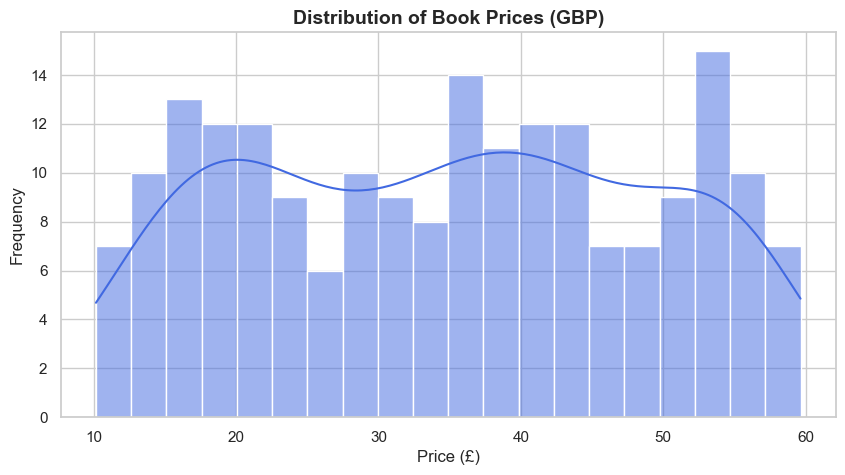

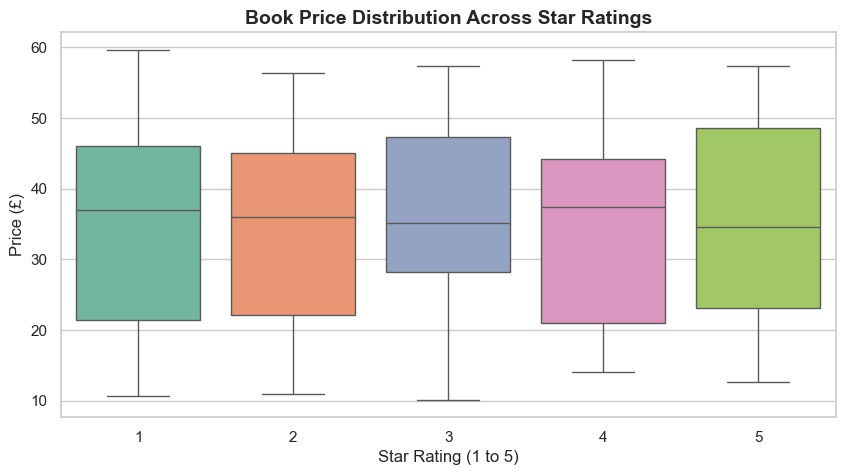

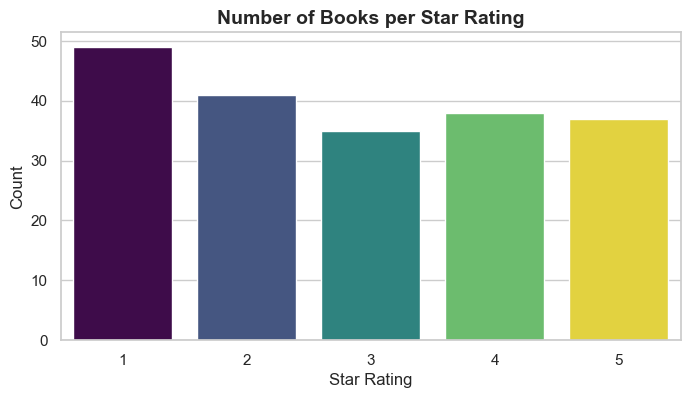

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style for professional-looking plots
sns.set_theme(style="whitegrid")

# Load our cleaned dataset
df = pd.read_csv('books_to_scrape_clean.csv')

# --- PLOT 1: Distribution of Book Prices ---
plt.figure(figsize=(10, 5))
sns.histplot(df['Price_GBP'], kde=True, color='royalblue', bins=20)
plt.title('Distribution of Book Prices (GBP)', fontsize=14, fontweight='bold')
plt.xlabel('Price (£)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

# --- PLOT 2: Price vs. Star Rating (Boxplot) ---
plt.figure(figsize=(10, 5))
sns.boxplot(x='Star_Rating', y='Price_GBP', data=df, hue='Star_Rating', palette='Set2', legend=False)
plt.title('Book Price Distribution Across Star Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating (1 to 5)', fontsize=12)
plt.ylabel('Price (£)', fontsize=12)
plt.show()

# --- PLOT 3: Count of Books by Star Rating ---
plt.figure(figsize=(8, 4))
sns.countplot(x='Star_Rating', data=df, order=sorted(df['Star_Rating'].unique()), hue='Star_Rating', palette='viridis', legend=False)
plt.title('Number of Books per Star Rating', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

In [14]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Suppress pandas future downcasting warnings
pd.set_option('future.no_silent_downcasting', True)

# 1. Load the cleaned dataset
df = pd.read_csv('books_to_scrape_clean.csv')

# 2. Feature Engineering: Extract numeric quantity safely
df['Stock_Quantity'] = df['Stock_Availability'].str.extract(r'\((\d+)\s+available\)')[0]
df['Stock_Quantity'] = pd.to_numeric(df['Stock_Quantity']).fillna(0).astype(int)

# 3. Define Features (X) and Target Variable (y)
X = df[['Star_Rating', 'Stock_Quantity']]
y = df['Price_GBP']

# 4. Split data into Training set (80%) and Testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 6. Make predictions on the test set
y_pred = model.predict(X_test)

# 7. Evaluate the model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- MODEL EVALUATION RESULTS ---")
print(f"Coefficients (Weights for Star Rating & Stock Quantity): {model.coef_}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

--- MODEL EVALUATION RESULTS ---
Coefficients (Weights for Star Rating & Stock Quantity): [0.25584102 0.        ]
Intercept: 33.80
Mean Squared Error (MSE): 232.73
Root Mean Squared Error (RMSE): 15.26
R-squared (R2) Score: -0.0085
